<a href="https://colab.research.google.com/github/mysteryea7107/Automobile-Price-Prediction-Using-Multiple-Regression/blob/main/Notebooks/Automobile_Price_Prediction_Using_Multiple_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Data manipulation, processing, and analysis libraries
import numpy as np
import numpy.random as random
import scipy as sp
from pandas import Series, DataFrame
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
%matplotlib inline

# Machine learning library
import sklearn

# Display up to three decimal places
%precision 3

'%.3f'

###Multiple Regression

Keywords: Target Variable, Explanatory Variables, Multicollinearity, Variable Selection Methods

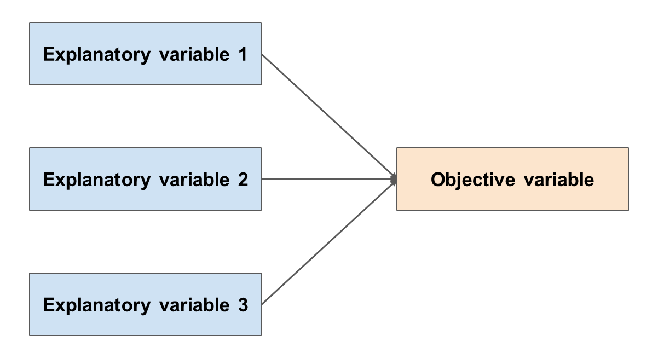

Importing Automobile Price Data

We will build a multiple regression model to predict automobile prices based on their attributes (such as size) using a dataset that contains the prices and attributes of automobiles. The data will be sourced from the following URL.

http://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data

In [ ]:
# Import
import requests, zipfile
import io

# Fetch automobile price data
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data'
res = requests.get(url).content

# Load the fetched data into a DataFrame object
auto = pd.read_csv(io.StringIO(res.decode('utf-8')), header=None)

# Set labels for the data columns
auto.columns =['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors',
                            'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height',
                            'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore',
                            'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

In [ ]:
print('Shape of the car data:{}'.format(auto.shape))

Shape of the car data:(205, 26)


It can be confirmed that the data consists of 205 rows and 26 columns.

Next, let's display the first five rows using the `head()` method.

In [ ]:
auto.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In this dataset, the price of the cars is set in the `price` column. Since we are trying to create a model to predict the price based on the car's attributes, the challenge is to build a model that predicts `price` using the values from the other columns.

To simplify the task, we will only use three explanatory variables: `horsepower`, `width`, and `height`. In other words, we will create a model that predicts the price variable based on the explanatory variables `horsepower`, `width`, and `height`.








Data Preparation

Input data may contain inappropriate or invalid entries. Therefore, the first step is to review the data and organize it appropriately.

#### Removing Inappropriate Data

When reviewing the data using the `head()` method, you may notice that there are entries with '?'. Many machine learning algorithms only handle numerical data, so preprocessing is required to remove non-numeric data, such as '?'.

Since our goal is to predict `price` from `horsepower`, `width`, and `height`, we need to delete any rows containing '?' in these variables. Specifically, we will convert '?' entries to missing values and then remove the rows containing these missing values. The following code can be used to check how many '?' entries are present in the four variables we are working with: `horsepower`, `width`, `height`, and `rice`.

In [ ]:
# Count the number of `?` in each column
auto = auto[['price', 'horsepower', 'width', 'height']]
auto.isin(['?']).sum()

,0
price,0
horsepower,0
width,0
height,0


You can see that there are '?' data mixed into the `price` and `horsepower` columns, so we will use a technique we learned before in Pandas to exclude them. By doing the following, the rows containing '?' will be removed. When executed, you can confirm that the number of rows has decreased.

In [ ]:
# Replace `?` with NaN and drop rows with NaN
auto = auto.replace('?', np.nan).dropna()
print('Shape of the car data:{}'.format(auto.shape))

Shape of the car data:(199, 4)


#### Type Conversion

Let's check the data types here. You can do so using the following code.

In [ ]:
print('Check data types (before type conversion)\n{}\n'.format(auto.dtypes))

Check data types (before type conversion)
price          object
horsepower     object
width         float64
height        float64
dtype: object



It can be confirmed that both price and horsepower are not numeric types. Therefore, we will use `to_numeric` to convert them to numeric types.

In [ ]:
auto = auto.assign(price=pd.to_numeric(auto.price))
auto = auto.assign(horsepower=pd.to_numeric(auto.horsepower))
print('Data type check (after type conversion\n{}'.format(auto.dtypes))

Data type check (after type conversion
price           int64
horsepower      int64
width         float64
height        float64
dtype: object


#### Correlation Check

With the above operations, all rows of the explanatory variables and the target variable have been processed to be free of missing values and in numeric data format. Next, we will check the correlation between each variable. You can use `corr()` as follows to check the correlation.

In [ ]:
auto.corr()



,price,horsepower,width,height
price,1.000000,0.810533,0.753871,0.134990
horsepower,0.810533,1.000000,0.615315,-0.087407
width,0.753871,0.615315,1.000000,0.309223
height,0.134990,-0.087407,0.309223,1.000000


Visualize using Seaborn

<Axes: >

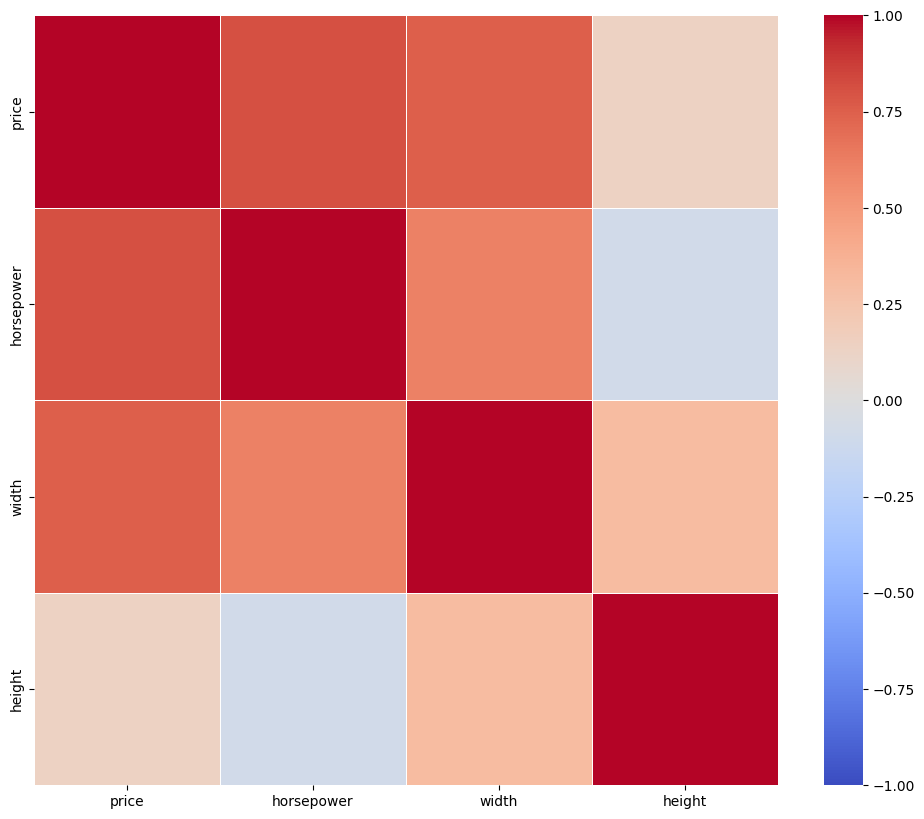

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size for a clean layout
plt.figure(figsize=(12, 10))

# Calculate correlation (numeric_only=True ensures non-numeric columns don't cause an error)
corr_matrix = auto.corr(numeric_only=True)

# Create the heatmap
sns.heatmap(
    corr_matrix,
    annot=False,  # Set to True if you want the numbers inside each cell (can get crowded with 26 columns)
    cmap="coolwarm",  # Color map (blue = negative correlation, red = positive)
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)

Since `price` is the target variable here, focusing on the other three variables, we notice that `width` and `horsepower` have a somewhat high correlation of around 0.6. This check is necessary because using highly correlated variables as explanatory variables in multiple regression can lead to **multi-collinearity**.

Multi-collinearity is a phenomenon where high correlation between variables causes an increase in the variance of regression coefficients, leading to a loss of coefficient significance. To avoid this, typically in multiple regression modeling, only a representative variable from groups of highly correlated variables is used. However, since this is an experiment, we won’t be strict about this; both `width` and `horsepower` will be included along with `height` in building the model.


Model Building and Evaluation

Now that we have the data, let's build the model. The following program creates a multiple regression model and examines its performance.


 The multiple regression model is built using the `LinearRegression`class. An instance is created with `model = LinearRegression()`, and the model is trained by loading the training data with `model.fit(X_train, y_train)`, completing the training process. Once trained, you can check the coefficient of determination, regression coefficients, and intercept. The coefficient of determination indicates how closely the predicted values of the target variable match the actual values of the target variable.

In the objective function of multiple regression analysis, $y$ represents the target value, and $ f(\textbf{x}) = w_1x_1 + w_2x_2 + w_3x_3 +\cdots + b $ represents the predicted value. The goal is to find the coefficients that minimize the following equation.

\begin{eqnarray}
\sum^n_{i=1}(y_i-f(\textbf{x}_i))^2
\end{eqnarray}

In [ ]:
# Import for data splitting (training data and test data)
from sklearn.model_selection import train_test_split

# Import for building the multiple regression model
from sklearn.linear_model import LinearRegression

 # Set `price` as the target variable and the rest as explanatory variables
X = auto.drop('price', axis=1)
y = auto['price']

# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Initialize and train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Display the coefficient of determination
print('Coefficient of determination (train):{:.3f}'.format(model.score(X_train, y_train)))
print('Coefficient of determination (test):{:.3f}'.format(model.score(X_test, y_test)))

# Display regression coefficients and intercept
print('\nRegression coefficients\n{}'.format(pd.Series(model.coef_, index=X.columns)))
print('Intercept: {:.3f}'.format(model.intercept_))

Coefficient of determination (train):0.748
Coefficient of determination (test):0.822

Regression coefficients
horsepower     113.744621
width         1490.942805
height         237.994729
dtype: float64
Intercept: -109617.097


<>:16: SyntaxWarning: invalid escape sequence '\_'
<>:17: SyntaxWarning: invalid escape sequence '\_'
<>:16: SyntaxWarning: invalid escape sequence '\_'
<>:17: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_733/162279529.py:16: SyntaxWarning: invalid escape sequence '\_'
  plt.xlabel('Actual Price ($y\_test$)', fontsize=12)
/tmp/ipykernel_733/162279529.py:17: SyntaxWarning: invalid escape sequence '\_'
  plt.ylabel('Predicted Price ($y\_pred$)', fontsize=12)


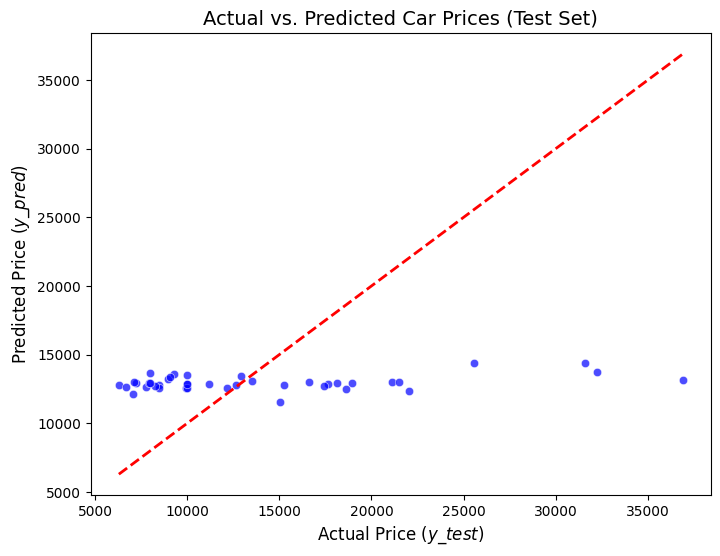

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate predictions for the test set
y_pred = model.predict(X_test)

# 2. Create the scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='b')

# Add a 45-degree reference line (perfect prediction line)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()],
             color='red', linestyle='--', linewidth=2)

plt.title('Actual vs. Predicted Car Prices (Test Set)', fontsize=14)
plt.xlabel('Actual Price ($y\_test$)', fontsize=12)
plt.ylabel('Predicted Price ($y\_pred$)', fontsize=12)
plt.show()

The coefficient of determination can be obtained using the `score` method. From the results above, we can see that the score for the training data is 0.748 and for the test data is 0.822. Since the scores for both the training and test data are close, we can conclude that this model is not overfitting.


- Initialization of the class for various model constructions：`model = LinearRegression()`
- Splitting the data into explanatory variables and target variables：$X$ and $y$
- Splitting into training and test data：`train_test_split(X, y, test_size=0.8, random_state=0)`
- Fitting the model using the training data (training)：`model.fit(X_train, y_train)`
- Testing the model's generalization performance using the test data：`model.score(X_test, y_test)`

In this case, we arbitrarily selected three explanatory variables—`horsepower`, `width`, and `height`—for the model building, but there are several statistical methods for selecting variables.


>Let's explore forward selection, backward elimination, and stepwise selection methods.

We will use the car price data utilized in the main text. For this data, set the target variable as `price` and use `symboling`, `compression-ratio`, `stroke` as the explanatory variables to build a multiple regression model. When doing this, use `train_test_split` to split the data into training and test sets so that 80% of the whole data set is the training data. Then, construct the model and calculate the model's score using the test data. When executing `train_test_split`, set the `random_state` option to 0.

In [ ]:
import io
import pandas as pd
import requests
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Load data
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data'
res = requests.get(url).content

auto = pd.read_csv(io.StringIO(res.decode('utf-8')), header=None)

auto.columns = [
    'symboling','normalized-losses','make','fuel-type' ,'aspiration','num-of-doors',
    'body-style','drive-wheels','engine-location','wheel-base','length','width','height',
    'curb-weight','engine-type','num-of-cylinders','engine-size','fuel-system','bore',
    'stroke','compression-ratio','horsepower','peak-rpm','city-mpg','highway-mpg','price'
]

# Select relevant columns
auto = auto[['price', 'symboling', 'compression-ratio', 'stroke']]

# Convert all columns to numeric, forcing '?' to become NaN (Not a Number)
auto = auto.apply(pd.to_numeric, errors='coerce')

# Drop rows that contain NaN values (the missing data represented by '?')
auto = auto.dropna()

# Set `price` as the target variable and the rest as explanatory variables
X = auto.drop('price', axis=1)
y = auto['price']

# Split into training and test data (80% training, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Initialize and train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Model construction and evaluation - Display the coefficient of determination
print('Coefficient of determination (train):{:.3f}'.format(model.score(X_train, y_train)))
print('Coefficient of determination (test):{:.3f}'.format(model.score(X_test, y_test)))

# Display regression coefficients and intercept
print('\nRegression coefficients\n{}'.format(pd.Series(model.coef_, index=X.columns)))
print('Intercept: {:.3f}'.format(model.intercept_))

Coefficient of determination (train):0.004
Coefficient of determination (test):0.030

Regression coefficients
symboling           -210.737660
compression-ratio     64.701313
stroke               795.713167
dtype: float64
Intercept: 9920.851


**Key Takeaway**: We have a very low score for both the training and testing data compared to when we used `horsepower`, `width`, `height` in the main text.. This is because the variables we used are not very good metrics for pricing cars:

*   `symboling`: This is an insurance risk rating, not a pricing metric like market value or production cost
*   `compression-ratio` and `stroke`: These are niche engine mechanics that show very weak linear correlation with the total vehicle price

As you can see, variables selection matters. Including numerical variables simply because they are available will not help your model if they lack real correlation with the target.


In [ ]:
### Automobile Price Prediction Using Multiple Regression
# Load data
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data'
res = requests.get(url).content

auto = pd.read_csv(io.StringIO(res.decode('utf-8')), header=None)

auto.columns = [
    'symboling','normalized-losses','make','fuel-type' ,'aspiration','num-of-doors',
    'body-style','drive-wheels','engine-location','wheel-base','length','width','height',
    'curb-weight','engine-type','num-of-cylinders','engine-size','fuel-system','bore',
    'stroke','compression-ratio','horsepower','peak-rpm','city-mpg','highway-mpg','price'
]

# Select relevant columns
auto = auto[['price', 'symboling', 'compression-ratio', 'stroke']]

# Convert all columns to numeric, forcing '?' to become NaN (Not a Number)
auto = auto.apply(pd.to_numeric, errors='coerce')

# Drop rows that contain NaN values (the missing data represented by '?')
auto = auto.dropna()

# Set `price` as the target variable and the rest as explanatory variables
X = auto.drop('price', axis=1)
y = auto['price']

# Split into training and test data (80% training, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Initialize and train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Model construction and evaluation - Display the coefficient of determination
print('Coefficient of determination (train):{:.3f}'.format(model.score(X_train, y_train)))
print('Coefficient of determination (test):{:.3f}'.format(model.score(X_test, y_test)))

# Display regression coefficients and intercept
print('\nRegression coefficients\n{}'.format(pd.Series(model.coef_, index=X.columns)))
print('Intercept: {:.3f}'.format(model.intercept_))

Coefficient of determination (train):0.004
Coefficient of determination (test):0.030

Regression coefficients
symboling           -210.737660
compression-ratio     64.701313
stroke               795.713167
dtype: float64
Intercept: 9920.851
